# AN2DL challenge
### Team: The four neurons

## 00 - Setup


In [58]:
SEED = 42

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from pathlib import Path
import kagglehub
import seaborn as sns


# Seed the Python, NumPy and PyTorch random number generators
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU when available; cuDNN then picks the fastest algorithms for the fixed input sizes
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Shared plot style: colour-blind-safe palette, light grid
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
sns.set_theme(style='whitegrid',
              palette=PALETTE,
              font_scale=1.1,
              rc={'grid.color': '#e1e0d9', 'axes.edgecolor': '#c3c2b7', 'lines.linewidth': 2})
rng = np.random.default_rng(SEED)

PyTorch version: 2.14.1+cpu
Device: cpu


## 01 - Data loading

In [59]:
# Download latest version
path = kagglehub.competition_download('an2dl2627')

DATA_DIR = Path(path)
print("Path to competition files:", DATA_DIR)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "sample_submission.csv")
# print(f"Train samples: {len(train_df)} | Test samples: {len(test_df)}")

CLASS_NAMES = {
    0: "Spaghetti alla rinfusa",
    1: "Gemelli",
    2: "Gnocchi",
    3: "Ravioli",
    4: "Penne",
    5: "Fusilli con la sbarra",
    6: "Fusilli stretti",
    7: "Riccioli",
    8: "Linguine",
    9: "Lasagna",
}

Path to competition files: /root/.cache/kagglehub/competitions/an2dl2627


## 02 - Exploratory Data Analisys
### 02.1 - Class distribution

Train nulls: {'id': 0, 'label': 0}
Test nulls : {'id': 0, 'label': 0}
Train samples: 4328 | Test samples: 14736

Imbalance ratio (max / min): 8.96x


,Class ID,Class Name,Count,Percentage (%)
0,0,Spaghetti alla rinfusa,213,4.92
1,1,Gemelli,345,7.97
2,2,Gnocchi,744,17.19
3,3,Ravioli,685,15.83
4,4,Penne,83,1.92
5,5,Fusilli con la sbarra,584,13.49
6,6,Fusilli stretti,565,13.05
7,7,Riccioli,477,11.02
8,8,Linguine,276,6.38
9,9,Lasagna,356,8.23


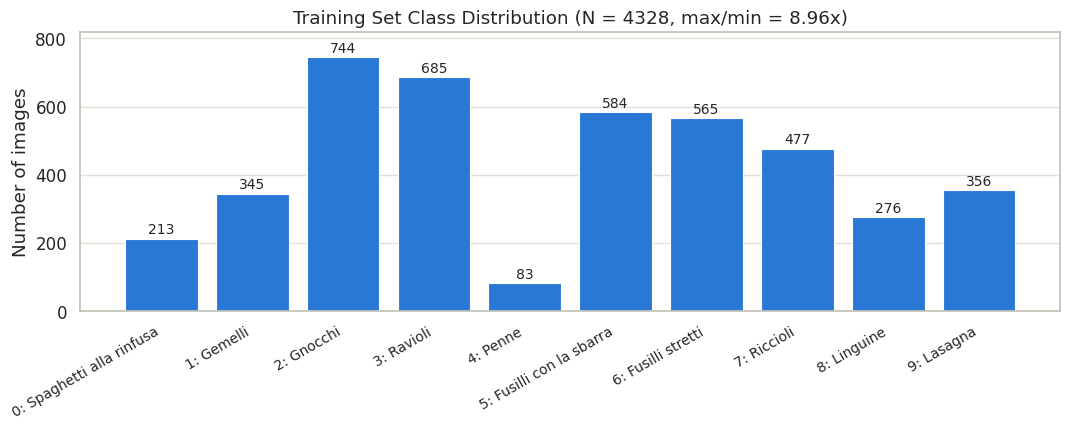

In [62]:
# Check missing values and verify image files on disk
print("Train nulls:", train_df.isna().sum().to_dict())
print("Test nulls :", test_df.isna().sum().to_dict())
print(f"Train samples: {len(train_df)} | Test samples: {len(test_df)}")

# Class counts table (adapted from Lecture 7; test labels are hidden on Kaggle)
counts = np.bincount(train_df["label"].values, minlength=len(CLASS_NAMES))
dist_df = pd.DataFrame({
    "Class ID": list(CLASS_NAMES.keys()),
    "Class Name": list(CLASS_NAMES.values()),
    "Count": counts,
    "Percentage (%)": np.round(100.0 * counts / len(train_df), 2),
})
print(f"\nImbalance ratio (max / min): {counts.max() / counts.min():.2f}x")
display(dist_df)

# Plot class distribution
fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [f"{c}: {name}" for c, name in CLASS_NAMES.items()]
bars = ax.bar(labels, counts, color=PALETTE[0], edgecolor="white", linewidth=0.8)

for bar, cnt in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        cnt + 5,
        f"{cnt}",
        ha="center",
        va="bottom",
        fontsize=10,
        #fontweight="bold",
    )

ax.set_ylabel("Number of images")
ax.set_title(f"Training Set Class Distribution (N = {len(train_df)}, max/min = {counts.max()/counts.min():.2f}x)")
ax.set_ylim(0, counts.max() * 1.1)
ax.grid(axis="x", visible=False)
plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()